[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/10_sweep_and_shell_pressure_drop.ipynb)

# 10 · Permeate sweep gas and shell-side pressure drop

Two refinements of the module models:

1. **Sweep gas.** A gas fed into the permeate channel at its closed end dilutes the permeate,
   lowers the fast-gas partial pressure on the permeate side and so raises the driving force. It
   is used in post-combustion CO₂ capture (Merkel et al., 2010, sweep the second stage with the
   boiler's combustion air) and in dehydration (a dry sweep).
2. **Shell-side pressure drop.** In rating mode, the feed flowing along the fibre bundle loses
   pressure as well as the permeate inside the bores.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## 1. Sweep gas in a CO₂-capture stage

Flue gas, 13 % CO₂, Polaris membrane (Merkel 2010), 1.1 bar feed and 0.22 bar permeate, counter-
current flow. The stage cut keeps its meaning, the fraction of the **feed** that crosses the
membrane; the permeate outlet carries that gas plus the sweep.

In [2]:
m  = Membrane(MEMBRANE_PRESETS["Polaris CO2/N2 (Merkel 2010)"])
xf = FEED_PRESETS["flue gas, 13% CO2 (Merkel 2010)"]
rows = []
for s in (0.0, 0.02, 0.05, 0.10, 0.20):
    r = solve_stage(m, xf, 0.12, 1.1, 0.22, "countercurrent", 1.0,
                    sweep_flow=s, sweep_composition={"N2": 1.0})
    rows.append({"sweep / feed": s, "CO2 recovery": r.recovery("CO2"),
                 "CO2 in retentate": r.x_ret[0], "CO2 in permeate": r.y_perm[0],
                 "area m2 per mol/s": r.area, "mass balance": r.mass_balance_error()})
pd.DataFrame(rows).set_index("sweep / feed")

,CO2 recovery,CO2 in retentate,CO2 in permeate,area m2 per mol/s,mass balance
sweep / feed,,,,,
0.00,0.4652,0.0790,0.5040,103.1198,2.2204e-16
0.02,0.5312,0.0693,0.4932,88.8513,4.3632e-14
0.05,0.6072,0.0580,0.4643,72.4106,1.1047e-14
0.10,0.6723,0.0484,0.3973,58.3228,1.7486e-15
0.20,0.7185,0.0416,0.2919,48.3232,2.2204e-16


At the same stage cut, a small sweep raises the CO₂ recovery and cuts the area sharply, because
the permeate-side CO₂ partial pressure at the retentate end falls towards zero. The price is a
more dilute permeate: the sweep leaves with it. That is why Merkel's design sends the swept
permeate back to the boiler instead of to the CO₂ product.

The figure shows the same effect along the module.

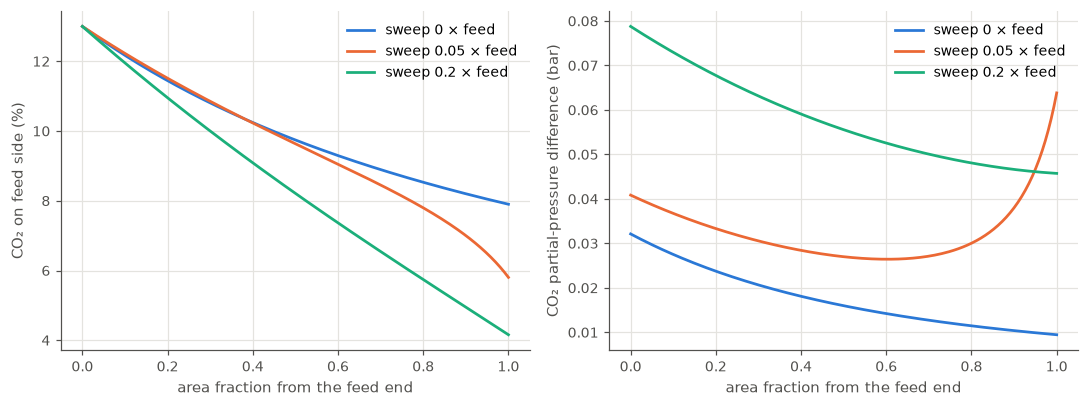

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k, s in enumerate((0.0, 0.05, 0.2)):
    r = solve_stage(m, xf, 0.12, 1.1, 0.22, "countercurrent", 1.0, profile=True,
                    sweep_flow=s, sweep_composition={"N2": 1.0})
    p = r.profile
    lab = f"sweep {s:g} × feed"
    ax[0].plot(p["area_fraction"], 100 * p["x"][0], color=gasmem_plot.SERIES[k], label=lab)
    ax[1].plot(p["area_fraction"], 1.1 * p["x"][0] - 0.22 * p["y"][0],
               color=gasmem_plot.SERIES[k], label=lab)
ax[0].set_ylabel("CO₂ on feed side (%)"); ax[1].set_ylabel("CO₂ partial-pressure difference (bar)")
for a in ax:
    a.set_xlabel("area fraction from the feed end"); a.legend()
plt.tight_layout()

### An air sweep carries oxygen into the retentate

With combustion air as the sweep, oxygen is on the permeate side but not in the feed, so it
permeates **backwards** into the retentate. The model handles this; here the O₂ permeance is
taken as 2.5 × N₂, an assumption for illustration.

In [4]:
m3 = Membrane({"CO2": 1000, "N2": 20, "O2": 50})
r = solve_stage(m3, {"CO2": 0.13, "N2": 0.87, "O2": 0.0}, 0.12, 1.1, 0.22, "countercurrent", 1.0,
                sweep_flow=0.1, sweep_composition={"N2": 0.79, "O2": 0.21})
print(r.summary())
print(f"mass-balance error {r.mass_balance_error():.1e}")

countercurrent: stage cut = 0.1200, area = 59.96 m2, p_h/p_l = 1.1/0.22 bar, sweep = 0.1 x feed (CO2 0, N2 0.79, O2 0.21)
  comp     feed  retent.    perm.  rec->perm
   CO2   0.1300   0.0476   0.4004     0.6775
    N2   0.8700   0.9493   0.5165     0.0398
    O2   0.0000   0.0031   0.0831        nan
mass-balance error 3.3e-16


### Check against an independent solver

The toolkit solves the counter-current problem by shooting from the retentate end. Here the same
problem is solved with SciPy's collocation boundary-value solver (`solve_bvp`), written from
scratch with the area as an unknown parameter.

In [5]:
from scipy.integrate import solve_bvp
xF, S, z, th = np.array([0.13, 0.87]), 0.1, np.array([0.0, 1.0]), 0.12
ph, pl, Q = 1.1 * BAR, 0.22 * BAR, m.Q

def f(s, Y, p):              # s = area fraction from the feed end; p[0] = total area
    N, P = Y[:2], Y[2:]
    J = Q[:, None] * (ph * N / N.sum(0) - pl * P / P.sum(0))
    return np.vstack([-p[0] * J, -p[0] * J])

def bc(Ya, Yb, p):
    return np.array([Ya[0] - xF[0], Ya[1] - xF[1], Yb[2] - S * z[0] - 1e-30,
                     Yb[3] - S * z[1], Yb[0] + Yb[1] - (1 - th)])

s = np.linspace(0, 1, 50)
Y0 = np.vstack([np.outer(xF, 1 - th * s), np.outer([0.1, 0.12], 1 - s) + np.outer(S * z, s)])
bvp = solve_bvp(f, bc, s, Y0, p=[50.0], tol=1e-8, max_nodes=100000)
r = solve_stage(m, xF, th, 1.1, 0.22, "countercurrent", 1.0, sweep_flow=S,
                sweep_composition={"N2": 1.0})
pd.DataFrame({"gasmem (shooting)": [r.area, r.x_ret[0]],
              "solve_bvp (collocation)": [bvp.p[0], bvp.y[0, -1] / bvp.y[:2, -1].sum()]},
             index=["area m2 per mol/s", "CO2 in retentate"])

,gasmem (shooting),solve_bvp (collocation)
area m2 per mol/s,58.3228,58.3228
CO2 in retentate,0.0484,0.0484


Sweeps also work in flowsheets: give a stage `StageSpec(..., sweep_ratio=0.1,
sweep_composition={"N2": 0.79, "O2": 0.21})`. The sweep then appears as an extra input stream
(`sweep 2` for stage 2) and is included in the flowsheet mass balance.

## 2. Shell-side pressure drop in a fixed module

Give the module a **packing fraction** φ (fibre cross-section over shell cross-section, typically
0.4–0.6). The feed then flows along the fibres through the free shell area, treated as laminar flow
in a channel of hydraulic diameter d<sub>h</sub> = d<sub>o</sub>(1−φ)/φ. Real bundles also lose
pressure at the ports and baffles; `shell_friction_factor` scales the coefficient to match a
measured pressure drop.

The case is biogas in a 1 744 m² module (the single-stage design of the README), fed at 1 000 and
2 000 Nm³/h.

In [6]:
mb  = Membrane(MEMBRANE_PRESETS["Polyimide CO2/CH4, a=35 (Makaruk 2010)"])
xfb = FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"]
rows = []
for flow in (1000, 2000):
    for phi, fric in ((None, 1.0), (0.5, 1.0), (0.6, 1.0), (0.6, 30.0)):
        mod = HollowFibreModule.for_area(1744, length=1.0, d_inner=200e-6, d_outer=400e-6,
                                         packing_fraction=phi, shell_friction_factor=fric)
        r = rate_module(mb, xfb, nm3h_to_mols(flow), 10, 1, mod, "countercurrent", profile=False)
        rows.append({"feed Nm3/h": flow, "packing": phi or "none", "friction factor": fric,
                     "shell dp bar": r.extra["shell_dp_bar"], "bore dp bar": r.extra["bore_dp_bar"],
                     "stage cut": r.theta, "CH4 retentate": r.x_ret[1]})
pd.DataFrame(rows).set_index(["feed Nm3/h", "packing", "friction factor"])

shell dp bar  bore dp bar  stage cut  \
feed Nm3/h packing friction factor                                         
1000       none    1.0                    0.0000       0.1045     0.4970   
           0.5     1.0                    0.0027       0.1045     0.4970   
           0.6     1.0                    0.0091       0.1045     0.4969   
                   30.0                   0.2791       0.1039     0.4938   
2000       none    1.0                    0.0000       0.2036     0.3810   
           0.5     1.0                    0.0066       0.2035     0.3809   
           0.6     1.0                    0.0223       0.2034     0.3807   
                   30.0                   0.6983       0.1977     0.3716   

                                    CH4 retentate  
feed Nm3/h packing friction factor                 
1000       none    1.0                     0.9763  
           0.5     1.0                     0.9763  
           0.6     1.0                     0.9763  
                   30.0                    0.9742  
2000       none    1.0                     0.8884  
           0.5     1.0                     0.8883  
           0.6     1.0                     0.8881  
                   30.0                    0.8788

With the bundle alone, the shell-side loss is a few millibar: the feed velocity in the shell is low
and the free area large. It matters when the measured module pressure drop is much larger
(ports, baffles, fouling), or at low feed pressure, where every 100 mbar is a large part of the
driving force. The profile below shows both pressures along the module for the high-friction case.

HollowFibreModule(area=1744 m2, n_fibres=1.388e+06, L=1 m, d_i=200 um, d_o=400 um, packing=0.6, D_shell=0.608 m)


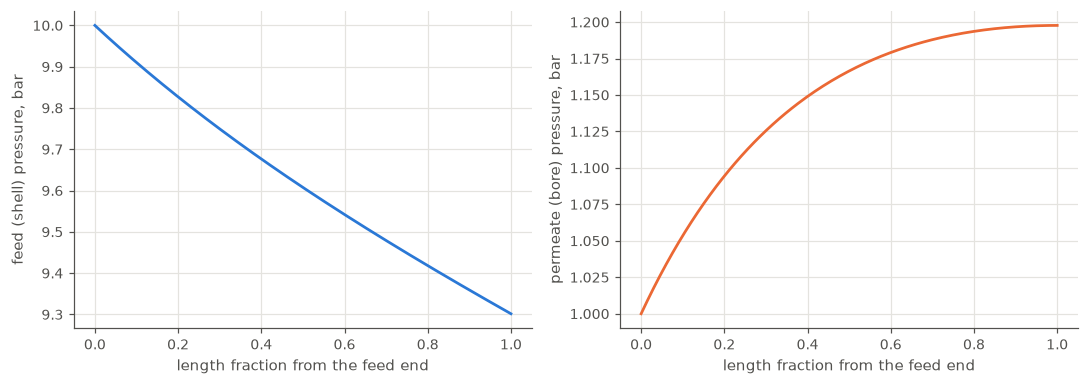

In [7]:
mod = HollowFibreModule.for_area(1744, packing_fraction=0.6, shell_friction_factor=30.0)
r = rate_module(mb, xfb, nm3h_to_mols(2000), 10, 1, mod, "countercurrent")
p = r.profile
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(p["area_fraction"], p["p_feed_bar"], color=gasmem_plot.SERIES[0])
ax[0].set_ylabel("feed (shell) pressure, bar")
ax[1].plot(p["area_fraction"], p["p_perm_bar"], color=gasmem_plot.SERIES[1])
ax[1].set_ylabel("permeate (bore) pressure, bar")
for a in ax:
    a.set_xlabel("length fraction from the feed end")
plt.tight_layout()
print(mod)